# Phase 2: Exploratory Analysis and Preregistration



## Part 1 — Data collection and exploratory analysis
### 1. Research question
**How do U.S. monthly temperature and precipitation relate to the business’s monthly hat sales, and does the relationship vary across different hat material?**

For our project, we are measuring sales data from a family-owned hat business (link: https://angelawilliam.com/) and comparing it with historical weather data from the NOAA (National Oceanic and Atmospheric Administration). We want to see *whether* certain *weather* conditions (pun not intended, lol) are associated with higher or lower hat sales.

We will focus more so on monthly sales quantity and average temperature and precipitation across the contiguous United States.

### 2. Data collection and cleaning
#### 2.1. Data sources and collection

We are using sales and product data from William's family business. And we are using the historical weather data from NOAA.

The business data comes from an export of the accounting software and includes transaction records, descriptions of the product, and inventory information.

For the NOAA: we downloaded the weather data from the NOAA's monthly climate dataset which contains historical temperature and precipitation measurements.

We're using 5 files:

| File | Use |
| --- | --- |
| `salesByCustomerDetail.CSV` | Invoice lines used to calculate monthly sales. |
| `itemData.CSV` | Product descriptions and types used to identify hats and filter merchandise. |
| `inventoryDataWithMoreDetail.csv` | Product catalog with HTML descriptions containing explicit `material:` fields, used to classify hat materials. |
| `TempreatureData.CSV` | Monthly average US temperatures |
| `PrecipitationData.CSV` | Monthly US precipitation (rain) |

[You may see the CSV files in this link](https://github.com/bobbybotbop/INFO2950/tree/main/csvs).

#### 2.1. Setup
We first import Python libraries to use for cleaning, analyzing and visualizing the data. All the data is stored in the `csvs` folder.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# All file paths are relative to the repository root.
plt.rcParams['figure.figsize'] = (10, 4)


#### 2.2. Load the business files

We load the three business datasets. The sales and catalog files come from the accounting software. The inventory detail file (`inventoryDataWithMoreDetail.csv`) is a separate product catalog export from the web storefront, with HTML descriptions that include explicit material fields. We check row counts and column names to confirm the files loaded correctly. We read all columns as text initially so that product IDs and other values aren't accidentally changed when importing the files.

In [2]:
sales_raw = pd.read_csv('csvs/salesByCustomerDetail.CSV', encoding='cp1252', dtype=str).fillna('')
catalog = pd.read_csv('csvs/itemData.CSV', encoding='cp1252', dtype=str).fillna('')
inventory_detail = pd.read_csv('csvs/inventoryDataWithMoreDetail.csv', encoding='utf-8-sig', dtype=str).fillna('')

print('Sales report rows:', len(sales_raw))
print('Catalog rows:', len(catalog))
print('Inventory detail rows:', len(inventory_detail))
print('Sales row types (blank = report heading or subtotal):')
display(sales_raw['Type'].value_counts())


Sales report rows: 32768
Catalog rows: 7866
Inventory detail rows: 931
Sales row types (blank = report heading or subtotal):


Type
Invoice    31877
             891
Name: count, dtype: int64

#### 2.3. Cleaning transactions and matching products

The original sales file includes invoices, headings, and subtotal rows. Since we're interested in actual sales, we filter the data to keep invoice entries.

We then convert dates and numerical columns into usable formats, removing characters such as dollar signs and commas with `regex`. We also extract the product IDs and match them with the product information file so that we can identify what was sold.

We keep the original row numbers to help trace records back to the source data, and we don't automatically delete duplicate-looking transactions since some may be legitimate sales.

One concern is that both transaction exports contain exactly 32,768 rows and appear to end partway through the records. This might indicate an export limit, so we still need to verify whether the data is complete.

In [3]:
# Keep invoice rows, rather than report headings and subtotals.
sales = sales_raw[sales_raw['Type'] == 'Invoice'].copy()
sales['source_csv_row'] = sales.index + 2
sales['date'] = pd.to_datetime(sales['Date'], format='%m/%d/%Y', errors='coerce')

# Clean the three numeric columns. Parentheses mean a negative amount.
for column in ['Qty', 'Amount', 'Sales Price']:
    sales[column] = sales[column].str.replace(',', '', regex=False)
    sales[column] = sales[column].str.replace('$', '', regex=False)
    sales[column] = sales[column].str.replace('(', '-', regex=False)
    sales[column] = sales[column].str.replace(')', '', regex=False)
    sales[column] = pd.to_numeric(sales[column], errors='coerce')
sales = sales.rename(columns={'Qty': 'quantity', 'Amount': 'amount', 'Sales Price': 'unit_price'})

# Sales item names contain an ID followed by a description in parentheses.
sales['item_id'] = sales['Item'].str.split(' (', n=1, regex=False).str[0].str.strip()
catalog['item_id'] = catalog['Item'].str.strip()
products = catalog[['item_id', 'Type', 'Description']].copy()
products = products.rename(columns={'Type': 'catalog_type', 'Description': 'catalog_description'})

# many_to_one checks that each item ID matches no more than one catalog row.
sales = sales.merge(products, on='item_id', how='left', validate='many_to_one')
print('Invoice lines:', len(sales))
print('Unmatched catalog lines:', sales['catalog_type'].isna().sum())
print('First invoice date:', sales['date'].min())
print('Last invoice date:', sales['date'].max())
print('Missing numeric values:')
display(sales[['quantity', 'amount', 'unit_price']].isna().sum())
print('Zero or negative quantity lines:', (sales['quantity'] <= 0).sum())
print('Duplicate-looking source lines retained:', sales_raw[sales_raw['Type'] == 'Invoice'].duplicated().sum())


Invoice lines: 31877
Unmatched catalog lines: 1
First invoice date: 2006-10-01 00:00:00
Last invoice date: 2026-08-13 00:00:00
Missing numeric values:


quantity         0
amount         466
unit_price    1089
dtype: int64

Zero or negative quantity lines: 422
Duplicate-looking source lines retained: 1


#### 2.4. Identifying hats and materials

Next, we filter the transactions to focus on hats. We use product descriptions and keywords such as "hat," "fedora," "cap," and "beanie" to identify relevant products. We also exclude transactions that aren't merchandise, such as services or shipping charges.

We then classify hats by material using `inventoryDataWithMoreDetail.csv`. Each product description in that file contains an explicit HTML field like `<li>material: 100% acrylic</li>` or `material: 100% polyester<br />`. We extract this with a regular expression (`material:\s*([^<\n]+)`) and normalize the result to one of our material categories: acrylic, cotton, wool, felt, polyester, leather, or straw (which includes paper-straw and raffia). "Wool felt" is treated as a single material (wool) rather than a blend. When the description contains two or more distinct materials we label it `mixed_or_ambiguous`.

When a product has no usable material classification in the detailed catalog, we fall back to material keywords in the accounting descriptions. Products that cannot be classified using either source remain `unknown`. These classifications are provisional and have not been independently verified.

Finally, we keep transactions with valid dates and positive quantities.

In [4]:
import re

def extract_material(desc):
    m = re.search(r'material:\s*([^<\n]+)', desc, re.IGNORECASE)
    if not m:
        return 'unknown'
    raw = re.sub(r'&[a-z#0-9]+;', ' ', m.group(1)).strip().lower()
    found = []
    if 'wool felt' in raw:
        found.append('wool')
    else:
        if 'wool' in raw:
            found.append('wool')
        if 'felt' in raw:
            found.append('felt')
    if 'cotton' in raw:
        found.append('cotton')
    if 'acrylic' in raw:
        found.append('acrylic')
    if 'polyester' in raw:
        found.append('polyester')
    if 'leather' in raw:
        found.append('leather')
    if 'straw' in raw or 'paper' in raw or 'raffia' in raw:
        found.append('straw')
    if not found:
        return 'unknown'
    if len(found) == 1:
        return found[0]
    return 'mixed_or_ambiguous'

# Build a material lookup from inventoryDataWithMoreDetail.csv descriptions.
detail = inventory_detail.copy()
detail['item_id'] = (detail['Product Code']
                     .str.strip()
                     .str.replace(r'\s+same as.*$', '', case=False, regex=True))
detail = detail.drop_duplicates('item_id')
detail['material_detail'] = detail['Description'].apply(extract_material)
material_lookup = detail.set_index('item_id')['material_detail']

# Combine descriptions and replace punctuation with spaces for word matching.
sales['description_text'] = sales['catalog_description'].fillna('') + ' ' + sales['Item']
sales['description_text'] = sales['description_text'].str.lower()
sales['words'] = sales['description_text'].str.replace(r'[^a-z]+', ' ', regex=True)
sales['words'] = ' ' + sales['words'] + ' '

# Flag common hat words.
hat_words = ['hat', 'hats', 'cap', 'caps', 'ivy', 'ivies', 'fedora', 'fedoras',
             'beanie', 'beanies', 'beret', 'berets', 'cloche', 'cloches',
             'fascinator', 'fascinators', 'visor', 'visors', 'bonnet', 'bonnets',
             'duckbill', 'newsboy', 'trilby', 'floppy', 'panama']
sales['candidate_hat'] = False
for word in hat_words:
    matches = sales['words'].str.contains(' ' + word + ' ', regex=False)
    sales.loc[matches, 'candidate_hat'] = True

# Exclude services, freight, and other non-merchandise catalog types.
merchandise_types = ['Inventory Part', 'Inventory Assembly', 'Non-inventory Part']
sales['candidate_hat'] = sales['candidate_hat'] & sales['catalog_type'].isin(merchandise_types)

# Keyword fallback for items not in the web-store catalog.
sales['material_kw'] = 'unknown'
kw_matches = pd.Series(0, index=sales.index)
for mat in ['wool', 'straw', 'cotton', 'polyester', 'acrylic', 'leather', 'felt']:
    m = sales['words'].str.contains(' ' + mat + ' ', regex=False)
    if mat == 'straw':
        m = m | sales['words'].str.contains(' raffia ', regex=False)
    sales.loc[m, 'material_kw'] = mat
    kw_matches += m.astype(int)
sales.loc[kw_matches > 1, 'material_kw'] = 'mixed_or_ambiguous'

# Use the detail lookup when available; fall back to keyword matching otherwise.
sales['material_detail'] = sales['item_id'].map(material_lookup).fillna('unknown')
sales['material'] = sales['material_detail'].where(
    sales['material_detail'] != 'unknown',
    sales['material_kw']
)

# Keep dated, positive-quantity candidate hats for preliminary gross-sales EDA.
keep = sales['candidate_hat'] & sales['date'].notna() & (sales['quantity'] > 0)
clean_sales = sales.loc[keep, ['source_csv_row', 'date', 'item_id', 'quantity',
                             'amount', 'unit_price', 'material']].copy()
clean_sales['month'] = clean_sales['date'].dt.to_period('M').dt.to_timestamp()
print('Retained candidate-hat invoice lines:', len(clean_sales))
display(clean_sales.groupby('material')['quantity'].sum().sort_values(ascending=False))


Retained candidate-hat invoice lines: 23072


material
unknown               666287
cotton                 32637
wool                   22615
felt                   12318
straw                  10978
acrylic                 7408
mixed_or_ambiguous      7085
leather                 2529
polyester               2514
Name: quantity, dtype: int64

#### 2.5. Monthly sales

We group the cleaned transactions by month and material, then addition all the recorded sales quantities.


This gives us a dataset showing how much of each hat material was sold during each month. We also check for months without sales records. Rather than assuming sales were zero during those months, we leave them missing because we don't know whether the business had no sales or whether records are incomplete.

In [5]:
# Sum quantities for each month and material.
monthly_sales = clean_sales.groupby(['month', 'material'])['quantity'].sum().reset_index()
monthly_sales = monthly_sales.rename(columns={'quantity': 'recorded_quantity'})

# Make a calendar so gaps remain visible in the time-series plots.
month_range = pd.date_range(clean_sales['month'].min(), clean_sales['month'].max(), freq='MS')
observed_month_count = clean_sales['month'].nunique()
print('Observed sales months:', observed_month_count)
print('Months without retained observations:', len(month_range) - observed_month_count)
display(monthly_sales.head())


Observed sales months: 234
Months without retained observations: 5


,month,material,recorded_quantity
0,2006-10-01,unknown,15259
1,2006-11-01,unknown,25537
2,2006-12-01,unknown,22356
3,2007-01-01,unknown,10310
4,2007-02-01,unknown,6086


#### 2.7 Loading weather data

For our weather data, we use NOAA's historical monthly temperature and precipitation records for the contiguous United States.

The files contain one row per year, with separate columns for each month. We select the national temperature and precipitation records, rather than individual states or regions.

Both datasets cover 1895 through September 2026, but we only use the months corresponding to our sales data (October 2006 through August 2026).

Record format help from the NOAA: https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/state-readme.txt


In [6]:
# Read the ID and 12 monthly values.
month_columns = ['01', '02', '03', '04', '05', '06',
                 '07', '08', '09', '10', '11', '12']
column_names = ['code'] + month_columns
temperature_raw = pd.read_csv('csvs/TempreatureData.CSV', sep=r'\s+',
                              header=None, names=column_names, dtype={'code': str})
precipitation_raw = pd.read_csv('csvs/PrecipitationData.CSV', sep=r'\s+',
                                header=None, names=column_names, dtype={'code': str})

# The six-character prefix selects region 110, division 0, and the variable.
temperature = temperature_raw[temperature_raw['code'].str[:6] == '110002'].copy()
precipitation = precipitation_raw[precipitation_raw['code'].str[:6] == '110001'].copy()
temperature['year'] = temperature['code'].str[6:10]
precipitation['year'] = precipitation['code'].str[6:10]
print('National temperature years:', len(temperature))
print('National precipitation years:', len(precipitation))
display(temperature[['year'] + month_columns].tail(2))


National temperature years: 132
National precipitation years: 132


,year,01,02,03,04,05,06,07,08,09,10,11,12
7792,2025,29.16,34.74,46.83,53.56,61.70,71.20,75.42,73.38,67.95,56.95,46.69,37.83
7793,2026,33.12,40.26,50.85,54.77,61.68,70.66,76.91,75.54,69.42,-99.90,-99.90,-99.90


#### 2.7. (a) Cleaning temperature data

We restructure the temperature data so that each row represents one month instead of one year. We also replace NOAA's missing-value codes with missing values in Python and convert temperatures from Fahrenheit to Celsius.

In [7]:
# Reshape the national temperature rows into one row per month.
temperature_monthly = temperature.melt(id_vars='year', value_vars=month_columns,
                                     var_name='month_number', value_name='temperature_f')
temperature_monthly['temperature_f'] = temperature_monthly['temperature_f'].replace(-99.90, float('nan'))
temperature_monthly['month'] = pd.to_datetime(temperature_monthly['year'] + '-' + temperature_monthly['month_number'] + '-01')
temperature_monthly['temperature_c'] = (temperature_monthly['temperature_f'] - 32) * 5 / 9
temperature_monthly = temperature_monthly[['month', 'temperature_c']].sort_values('month')
print('Missing national temperature months:', temperature_monthly['temperature_c'].isna().sum())
display(temperature_monthly.tail())


Missing national temperature months: 3


,month,temperature_c
1055,2026-08-01,24.188889
1187,2026-09-01,20.788889
1319,2026-10-01,NaN
1451,2026-11-01,NaN
1583,2026-12-01,NaN


#### 2.7. (b) Cleaning Precipitation Data

And same thing for precipitation, converting the data into monthly observations and handling missing values. We also convert the measurements from inches to millimeters so that we're using metric units consistently.

In [8]:
# Reshape the national precipitation rows into one row per month.
precipitation_monthly = precipitation.melt(id_vars='year', value_vars=month_columns,
                                         var_name='month_number', value_name='precipitation_in')
precipitation_monthly['precipitation_in'] = precipitation_monthly['precipitation_in'].replace(-9.99, float('nan'))
precipitation_monthly['month'] = pd.to_datetime(precipitation_monthly['year'] + '-' + precipitation_monthly['month_number'] + '-01')
precipitation_monthly['precipitation_mm'] = precipitation_monthly['precipitation_in'] * 25.4
precipitation_monthly = precipitation_monthly[['month', 'precipitation_mm']].sort_values('month')
print('Missing national precipitation months:', precipitation_monthly['precipitation_mm'].isna().sum())
display(precipitation_monthly.tail())


Missing national precipitation months: 3


,month,precipitation_mm
1055,2026-08-01,58.674
1187,2026-09-01,68.326
1319,2026-10-01,NaN
1451,2026-11-01,NaN
1583,2026-12-01,NaN


#### 2.8. Combining sales and weather data

Once both datasets are cleaned, we merge temperature and precipitation into a single monthly weather dataset.

We then join this with our monthly hat sales data using the month as the matching variable. This gives us a dataset containing recorded sales quantities for each material, along with the temperature and precipitation for that month.

Our merged dataset contains 999 rows across 234 months with recorded sales. Every row successfully matches a temperature and precipitation value.

There are also five months in the overall time range without retained sales observations. We leave these missing rather than assuming there were zero sales.

In [9]:
# Make one national weather row per month.
weather_monthly = temperature_monthly.merge(precipitation_monthly, on='month',
                                           how='outer', validate='one_to_one')
weather_monthly = weather_monthly.sort_values('month')
start_month = monthly_sales['month'].min()
end_month = monthly_sales['month'].max()
weather_monthly = weather_monthly[weather_monthly['month'].between(start_month, end_month)].copy()

# Each weather month can match several sales material rows.
analysis_data = monthly_sales.merge(weather_monthly, on='month', how='left', validate='many_to_one')
print('Sales month-material rows before merge:', len(monthly_sales))
print('Rows after merge:', len(analysis_data))
print('Missing weather values in merged data:')
display(analysis_data[['temperature_c', 'precipitation_mm']].isna().sum())
display(analysis_data.head())


Sales month-material rows before merge: 999
Rows after merge: 999
Missing weather values in merged data:


temperature_c       0
precipitation_mm    0
dtype: int64

,month,material,recorded_quantity,temperature_c,precipitation_mm
0,2006-10-01,unknown,15259,11.427778,73.660
1,2006-11-01,unknown,25537,6.711111,62.484
2,2006-12-01,unknown,22356,2.538889,65.278
3,2007-01-01,unknown,10310,-0.361111,56.388
4,2007-02-01,unknown,6086,0.227778,44.450


### 3. Data description

#### What does our dataset contain?

Our final dataset, `analysis_data` contains 999 rows covering 234 months of sales records. Each row represents the total recorded sales quantity for a particular hat material in a given month.

There are 5 columns:

| Column | Meaning |
| --- | --- |
| `month` | Month of the recorded sales (1st day of the month). |
| `material` | Hat material. |
| `recorded_quantity` | Total positive sales quantity for that material during the month. |
| `temperature_c` | Average monthly temperature across US in °C. |
| `precipitation_mm` | Average monthly precipitation across the US, in mm. |

#### Why was this dataset created?

The original sales and inventory data was collected by William's family business for accounting. NOAA collects weather data to monitor the history of climate conditions.

For this project, we combined these sources to investigate whether temperature and precipitation are related to hat sales, and whether this relatoinship differs between materials.

#### How was the dataset created?

We started with sales/product inventory from the business accounting software, as well as monthly temp/precipitation data from NOAA.

We cleaned the sales records, converted dates and quantities, identified hats, assigned materials using explicit catalog fields with description keywords as a fallback, and grouped sales quantities by month and material.

For weather: we selected NOAA contiguous (continental) US observations, converted the measurements into metric units, and reorganized it into monthly rows.

(All these steps and details documented in the Section above, Section 2).

#### What factors might affect what was recorded?

Our sales data only represents purchases recorded by the business, not necessarily all customer demand of all hats in the USA. For example, if an item was out of stock, the business may have lost potential sales that wouldn't appear in the data.

The accounting exports may also be incomplete, and some product descriptions don't specify the material of the hat. Additionally, the weather data represents national averages rather than the specific locations of customers.

#### What preprocessing was done?

As stated in the section above, we filtered the sales records, standardized dates and values, and aggregated sales by month. Similarly for weather, we converted data into consistent units before merging the datasets.


#### Were people aware their data was being collected?

The sales records were originally collected as part of normal business operations, rather than for this research project. We received the data through William's family business (who are OK with us using the data).

Our research does not need individual customer names or any identifying information.

The weather data comes from the official NOAA website and is public domain.

#### Where can the original data be found?

The NOAA weather data is publicly available from the NOAA National Centers for Environmental Information. [Here is a link](https://www.ncei.noaa.gov/monitoring-content/data/us/climdiv/monthly/current/)

The original business data is private. Our group stores the csv files in [our GitHub CSV folder](https://github.com/bobbybotbop/INFO2950/tree/366262c76446df634e82f1028c0068cf396e9db2/csvs), but customer information and other sensitive business records should not be shared publicly.



### 4. Data limitations and implications
- **Incomplete sales records:** Both accounting exports contain exactly 32,768 rows, which suggests they may have been cut off. We also have five months without recorded sales, and August 2026 is incomplete. This could make our monthly sales totals inaccurate, especially when looking at long-term trends. For example, a decrease in recorded sales might actually reflect missing transactions rather than a decline in customer demand.
- **Missing material information:** Around 88.1% of our recorded sales quantity has an unknown or ambiguous material. We classify materials using two sources: explicit `material:` fields from the web-store product catalog, and keyword matching on the accounting catalog descriptions as a fallback. The web-store catalog only covers 931 current products, so most historical items rely on keyword matching. The high proportion of unknown materials reflects a broader data collection gap: the business did not closely document product details before it began selling online, and since many of those older products are no longer sold, it would be very difficult to go back and retrieve their material types now. We may still be missing or incorrectly classifying certain products. This is especially important for our second hypothesis, since the cotton and wool products we can identify might not represent the business's actual sales mix. We also can't assume that missing material information is evenly distributed across different years or seasons.
- **Geographic differences:** Our weather data represents averages across the contiguous United States, but the business might sell more hats in certain regions. For example, customers in New York and Florida experience very different weather conditions. Using national averages could make it harder to identify relationships between weather and sales in specific markets.
- **Other factors affecting sales:** Hat sales could also be influenced by fashion trends, wholesale orders, promotions, inventory availability, or changes in the business over time. Some of these might follow seasonal patterns, making it difficult to separate their effects from weather.


Full range: 2006-10 to 2026-08 (239 months)
Months with at least one invoice: 235
Months with no invoices at all: 4
  2010-05
  2010-06
  2010-07
  2020-04


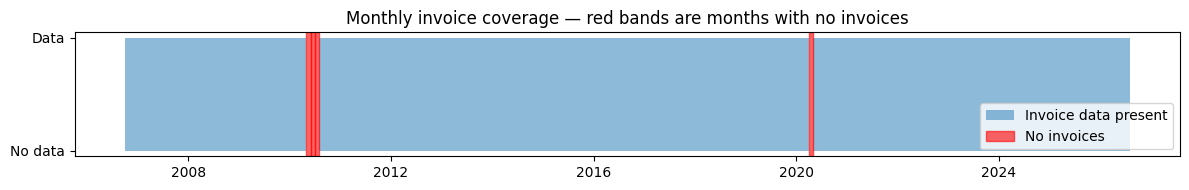

In [10]:
# Show which months in the full date range have no invoice records at all.
sales_months = (
    sales[sales['date'].notna()]
    .assign(month=lambda df: df['date'].dt.to_period('M').dt.to_timestamp())
    ['month']
    .drop_duplicates()
    .sort_values()
)

full_range = pd.date_range(sales_months.min(), sales_months.max(), freq='MS')
gap_months = full_range[~full_range.isin(sales_months)]

print(f'Full range: {sales_months.min().strftime("%Y-%m")} to {sales_months.max().strftime("%Y-%m")} ({len(full_range)} months)')
print(f'Months with at least one invoice: {len(sales_months)}')
print(f'Months with no invoices at all: {len(gap_months)}')
for m in gap_months:
    print(f'  {m.strftime("%Y-%m")}')

# Plot coverage across the full range — red bands are the gap months.
coverage = pd.Series(1, index=sales_months.values).reindex(full_range, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 2))
ax.fill_between(coverage.index, coverage.values, step='post', alpha=0.5, label='Invoice data present')
for i, m in enumerate(gap_months):
    ax.axvspan(m, m + pd.DateOffset(months=1), color='red', alpha=0.6,
               label='No invoices' if i == 0 else '')
ax.set_yticks([0, 1])
ax.set_yticklabels(['No data', 'Data'])
ax.set_title('Monthly invoice coverage — red bands are months with no invoices')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### 5. Exploratory data analysis

Before running the analyzes, we wanted to get a better understanding of our data. We looked at overall sales quantities, differences between materials, and how both sales and weather change over time.

#### 5.1. Summary statistics

We looked at Mean/median/range to understand typical sales quantities. We also calculated how much of our sales quantity has unknown or ambigious material.



In [11]:
# Summarize sales. Reindexing makes missing calendar months visible as NaN.
monthly_total = clean_sales.groupby('month')['quantity'].sum().reindex(month_range)
print('Invoice-line quantity:')
display(clean_sales['quantity'].describe().round(2))
print('Observed monthly total quantity:')
display(monthly_total.describe().round(2))

uncertain = clean_sales['material'].isin(['unknown', 'mixed_or_ambiguous'])
unknown_share = clean_sales.loc[uncertain, 'quantity'].sum() / clean_sales['quantity'].sum()
print('Percent of quantity with unknown/ambiguous material:', round(100 * unknown_share, 1))


Invoice-line quantity:


count    23072.00
mean        33.13
std        107.98
min          1.00
25%          6.00
50%         12.00
75%         24.00
max       4260.00
Name: quantity, dtype: float64

Observed monthly total quantity:


count      234.00
mean      3266.54
std       4873.24
min         35.00
25%        650.00
50%       1528.50
75%       3884.75
max      45756.00
Name: quantity, dtype: float64

Percent of quantity with unknown/ambiguous material: 88.1


#### 5.2. Sales over time

We plot total monthly sales quantities to see how sales have changed over time.


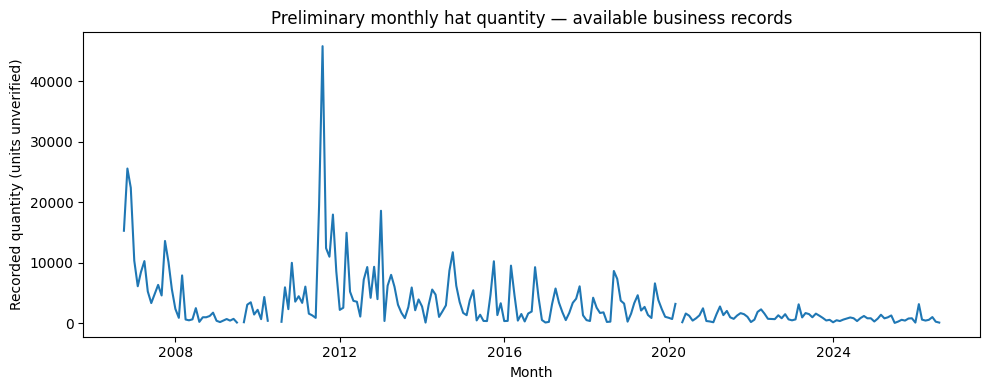

In [12]:
# Plot monthly quantities, leaving unknown months as gaps.
plt.figure(figsize=(10, 4))
plt.plot(monthly_total.index, monthly_total.values)
plt.title('Preliminary monthly hat quantity — available business records')
plt.xlabel('Month')
plt.ylabel('Recorded quantity (units unverified)')
plt.tight_layout()
plt.show()


#### 5.3. Material composition and invoice quantities

Next, we compare the total recorded sales quantity for each material category. This helps us understand which materials are most common in our dataset and how much information is missing.

We also plot the distribution of individual invoice quantities. We use a logarithmic scale because some orders are much larger than others, making it difficult to see the smaller orders on a regular scale.

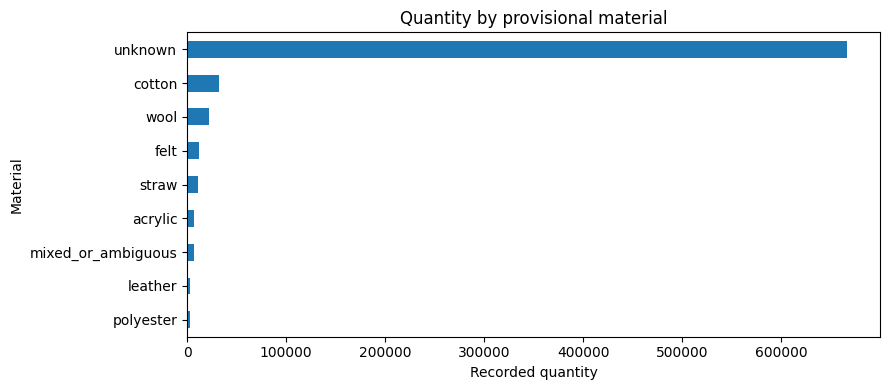

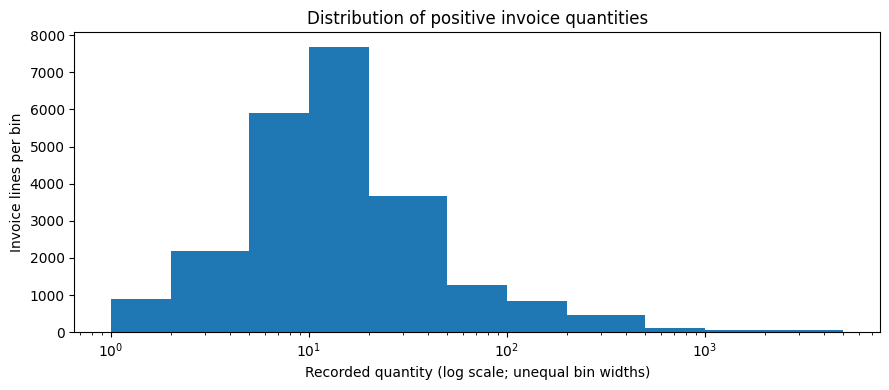

In [13]:
# Compare total recorded quantities by provisional material.
material_totals = clean_sales.groupby('material')['quantity'].sum().sort_values()
material_totals.plot(kind='barh', figsize=(9, 4))
plt.title('Quantity by provisional material')
plt.xlabel('Recorded quantity')
plt.ylabel('Material')
plt.tight_layout()
plt.show()

# Use wider bins for larger orders and label the axis in original quantities.
plt.figure(figsize=(9, 4))
plt.hist(clean_sales['quantity'], bins=[1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 5000])
plt.xscale('log')
plt.title('Distribution of positive invoice quantities')
plt.xlabel('Recorded quantity (log scale; unequal bin widths)')
plt.ylabel('Invoice lines per bin')
plt.tight_layout()
plt.show()


#### 5.4. Material sales over time

We then compare monthly sales for cotton, felt, and wool, which are the three largest material categories that we could identify.

We want to see whether these materials follow similar sales patterns throughout the year or whether some materials appear to sell more during certain periods. However, these comparisons are limited by the large proportion of products without a clear material classification.

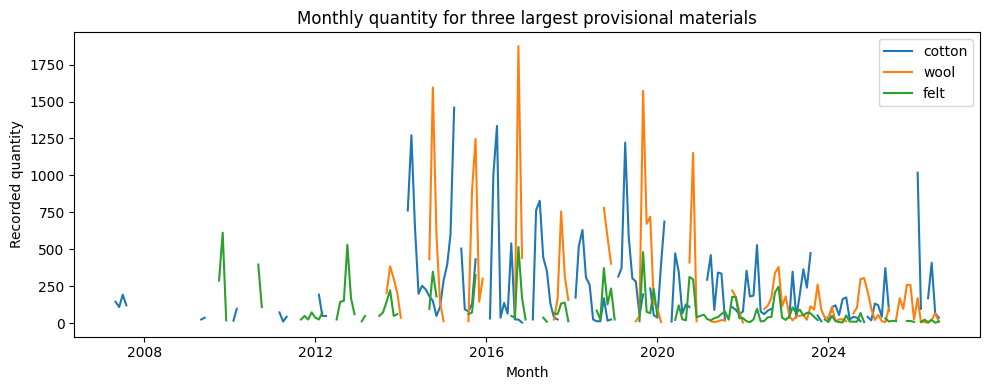

In [14]:
# Find the three largest named material groups.
known = monthly_sales[~monthly_sales['material'].isin(['unknown', 'mixed_or_ambiguous'])]
material_totals = known.groupby('material')['recorded_quantity'].sum().sort_values(ascending=False)
top_materials = material_totals.head(3).index

plt.figure(figsize=(10, 4))
for material in top_materials:
    material_data = known[known['material'] == material]
    quantities = material_data.set_index('month')['recorded_quantity'].reindex(month_range)
    plt.plot(quantities.index, quantities.values, label=material)
plt.title('Monthly quantity for three largest provisional materials')
plt.xlabel('Month')
plt.ylabel('Recorded quantity')
plt.legend()
plt.tight_layout()
plt.show()


#### 5.5 Weather over time

And finally we look at monthly temperature and precipitation rates across the contiguous US over the same period as our sales data.


,temperature_c,precipitation_mm
count,239.00,239.00
mean,12.10,65.62
std,8.42,14.80
min,-1.58,24.38
25%,4.59,56.39
50%,11.98,65.28
75%,20.31,75.06
max,24.95,113.54


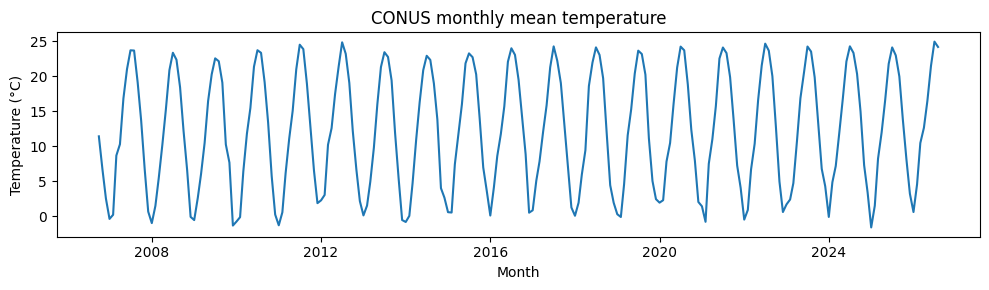

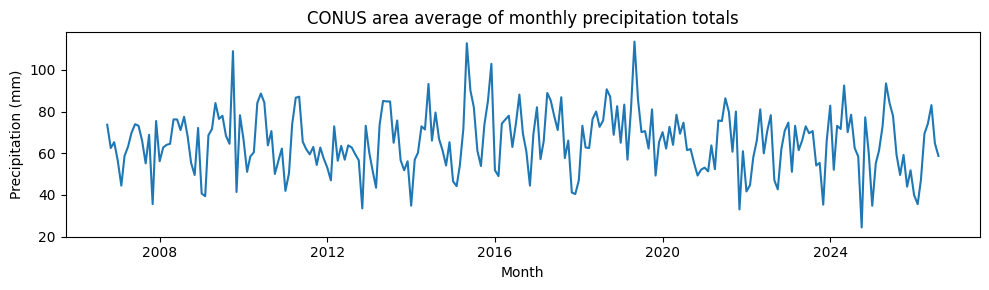

In [15]:
# Describe the national weather series within the sales date range.
display(weather_monthly[['temperature_c', 'precipitation_mm']].describe().round(2))

plt.figure(figsize=(10, 3))
plt.plot(weather_monthly['month'], weather_monthly['temperature_c'])
plt.title('CONUS monthly mean temperature')
plt.xlabel('Month')
plt.ylabel('Temperature (°C)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 3))
plt.plot(weather_monthly['month'], weather_monthly['precipitation_mm'])
plt.title('CONUS area average of monthly precipitation totals')
plt.xlabel('Month')
plt.ylabel('Precipitation (mm)')
plt.tight_layout()
plt.show()


#### 5.6. Weather and Hat Sales

Now that we've looked at sales and weather separately, we want to see how they relate to each other.

We plot monthly sales quantities against temperature and precipitation to look for any initial patterns. Each point represents one month of sales.

We exclude August 2026 because the sales records only cover part of that month. We're not running our proposed regression models yet; these plots are just to help us understand the data before the next phase.

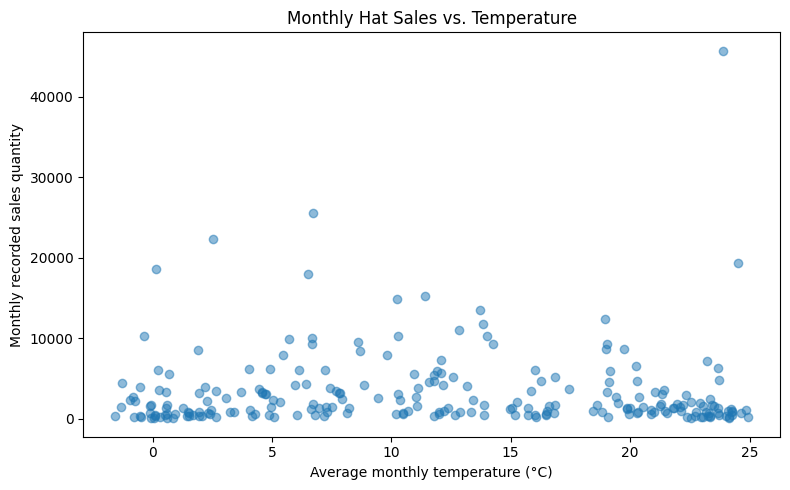

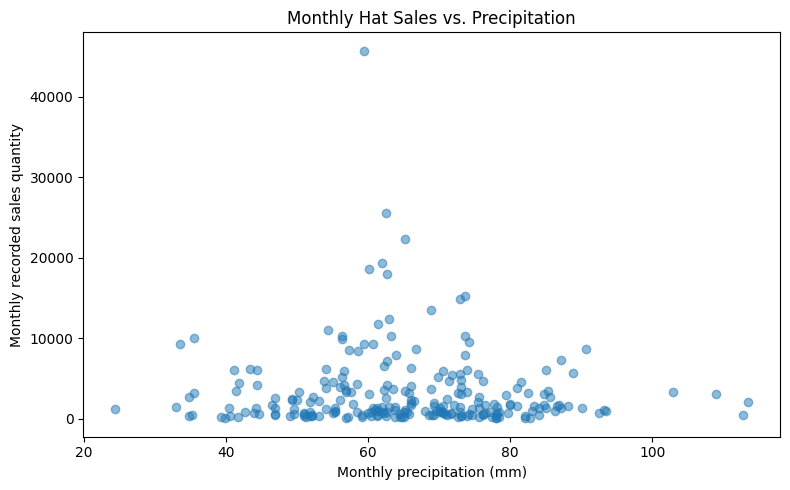

In [16]:

# Sum sales across all materials to get one total per month.

sales_totals = (
    monthly_sales.groupby('month', as_index=False)
    ['recorded_quantity'].sum()
)

# Match each sales month with its temperature and precipitation.
weather_sales = sales_totals.merge(
    weather_monthly,
    on='month',
    how='inner',
    validate='one_to_one'
)

# Exclude August 2026 because it is an incomplete sales month.
weather_sales = weather_sales[
    weather_sales['month'] < '2026-08-01'
].copy()

# Explore temperature versus sales.
plt.figure(figsize=(8, 5))
plt.scatter(
    weather_sales['temperature_c'],
    weather_sales['recorded_quantity'],
    alpha=0.5
)
plt.xlabel('Average monthly temperature (°C)')
plt.ylabel('Monthly recorded sales quantity')
plt.title('Monthly Hat Sales vs. Temperature')
plt.tight_layout()
plt.show()

# Explore precipitation versus sales.
plt.figure(figsize=(8, 5))
plt.scatter(
    weather_sales['precipitation_mm'],
    weather_sales['recorded_quantity'],
    alpha=0.5
)
plt.xlabel('Monthly precipitation (mm)')
plt.ylabel('Monthly recorded sales quantity')
plt.title('Monthly Hat Sales vs. Precipitation')
plt.tight_layout()
plt.show()


#### 5.7. Interpretation of the EDA


- Sales quantities vary significantly. We have 23,072 retained invoice lines covering 234 months. The median invoice quantity is 12, while the mean is 33.13, suggesting that some unusually large orders increase the average. Monthly totals also vary considerably, with a median of 1,528.5 and a mean of 3,266.54.

- Material information is limited. Around 88.1% of recorded sales quantity falls into the unknown or ambiguous material categories. This is largely because the business did not closely document product details before it began selling online, and since many of those older products are no longer sold, retrieving their material types would be very difficult. The web-store catalog only covers 931 currently listed products, leaving most historical transactions without an explicit material field. `monthly_sales` and `analysis_data` exclude these rows, leaving 649 month-material rows with an identified material.

- Some sales records may be missing. There are five months in our overall time range without retained sales observations, which we will need to investigate.

- The weather data is complete for the months we're analyzing. All 649 month-material observations have corresponding temperature and precipitation measurements. Across the 239-month period, the average temperature was 12.10°C and average monthly precipitation was 65.62 mm.

Based on these findings, we're keeping our original research question but clarifying that we're using national weather averages rather than weather conditions for individual customers.


#### 5.8. Unknown material diagnosis and filtered dataset

We investigate where the 88% uncategorized quantity comes from — by time and by product — and then rebuild the monthly sales and analysis datasets using only rows with an identified material.

In [ ]:
# Classify each invoice line as known or not.
clean_sales['material_known'] = ~clean_sales['material'].isin(['unknown', 'mixed_or_ambiguous'])

monthly_known   = clean_sales[clean_sales['material_known']].groupby('month')['quantity'].sum()
monthly_unknown = clean_sales[~clean_sales['material_known']].groupby('month')['quantity'].sum()

# Align both series to the full calendar so gaps are visible.
monthly_known   = monthly_known.reindex(month_range, fill_value=0)
monthly_unknown = monthly_unknown.reindex(month_range, fill_value=0)
monthly_total_qty = (monthly_known + monthly_unknown).replace(0, float('nan'))

unknown_share_by_month = (monthly_unknown / monthly_total_qty * 100)

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

axes[0].stackplot(month_range,
                  monthly_unknown.values,
                  monthly_known.values,
                  labels=['unknown/ambiguous', 'known material'],
                  alpha=0.7)
axes[0].set_ylabel('Recorded quantity')
axes[0].set_title('Monthly hat quantity: known vs unknown material')
axes[0].legend(loc='upper left')

axes[1].plot(month_range, unknown_share_by_month.values, color='tab:red')
axes[1].axhline(50, linestyle='--', color='grey', linewidth=0.8, label='50% threshold')
axes[1].set_ylabel('Unknown share (%)')
axes[1].set_title('Unknown material share per month')
axes[1].set_ylim(0, 105)
axes[1].legend()

plt.tight_layout()
plt.show()

# Print the first and last months where known material quantity > 0.
first_known_month = monthly_known[monthly_known > 0].index.min()
last_known_month  = monthly_known[monthly_known > 0].index.max()
print(f'First month with any known-material sales: {first_known_month:%Y-%m}')
print(f'Last  month with any known-material sales: {last_known_month:%Y-%m}')

# Print the first month where known material exceeds 50% of monthly quantity.
majority_known_months = unknown_share_by_month[unknown_share_by_month < 50].index
if len(majority_known_months):
    print(f'First month where known material > 50% of quantity: {majority_known_months[0]:%Y-%m}')
else:
    print('Known material never exceeds 50% of monthly quantity in any single month.')

In [20]:
# Annual known-material share.
clean_sales['year'] = clean_sales['date'].dt.year

annual = clean_sales.groupby('year').agg(
    total_qty=('quantity', 'sum'),
    known_qty=('quantity', lambda x: x[clean_sales.loc[x.index, 'material_known']].sum())
).assign(known_pct=lambda df: df['known_qty'] / df['total_qty'] * 100).round(1)

print('Annual known-material coverage:')
display(annual[['total_qty', 'known_qty', 'known_pct']])

# Identify the first year where known material >= 5% of annual quantity.
threshold_year = annual[annual['known_pct'] >= 5].index.min()
if pd.isna(threshold_year):
    print('Known material never reaches 5% of annual quantity in any year.')
else:
    print(f'First year where known material >= 5% of annual quantity: {threshold_year:.0f}')
threshold_year_10 = annual[annual['known_pct'] >= 10].index.min()
if pd.isna(threshold_year_10):
    print('Known material never reaches 10% of annual quantity in any year.')
else:
    print(f'First year where known material >= 10% of annual quantity: {threshold_year_10:.0f}')

Annual known-material coverage:


,total_qty,known_qty,known_pct
year,,,
2006,63152,0,0.0
2007,88515,708,0.8
2008,20277,27,0.1
2009,10876,990,9.1
2010,29474,1312,4.5
2011,132475,2212,1.7
2012,67020,1952,2.9
2013,59184,1894,3.2
2014,52042,8271,15.9


First year where known material >= 5% of annual quantity: 2009
First year where known material >= 10% of annual quantity: 2014


#### 5.8 Findings: unknown-material diagnosis

**Where do the unknowns come from?**
Unknown-material quantity is spread broadly across many products and is predominantly a historical data-quality issue. The unknown share remains above 50% of monthly quantity in every month through at least early 2018, reflecting the large volume of pre-catalog products for which no material field was ever recorded.

The annual known-material share rises slowly from 2006, reaching 5% for the first time in 2009. Known materials first exceed 10% of annual quantity in 2014.

**Is there a clean time window?**
Known-material sales exist from 2007-05 to 2026-08. However, the annual known-material share does not reach 10% until 2014, making the period from 2014 onward the most defensible window for regression restricted to known materials.

**Filtered dataset summary:**
`monthly_sales` and `analysis_data` are restricted to invoice lines with an identified material, giving 649 month-material rows across 198 months with known-material records. The original 23,072 invoice lines cover 234 months, but 88.1% of recorded quantity belongs to unknown or mixed/ambiguous products.

### 6. Questions for peer reviewers and project mentor — Part 1

1. Our sales exports appear to be cut off at 32,768 rows. Is there a good way to check whether we're missing transactions and how much this might affect our analysis?
2. Would using national average weather data be sufficient for our research question?
3. Many products don't have clearly identified materials. Would it make more sense to focus on fewer material categories, or is there a better approach to classifying them?
4. Are there any other variables we should consider before running our models, such as seasonal trends or changes in the business over time?



## Part 2 — Preregistration of analyses

**Preregistration Statement 1: Weather and total monthly sales**

Hypothesis: We expect lower temperatures to be associated with higher monthly hat sales, even after accounting for seasonality and changes over time. We also expect precipitation to have a relationship with sales, although we don't have a strong prediction about its direction.

Proposed analysis: We will calculate the business's total recorded hat quantity for each month and use multiple linear regression to examine its relationship with temperature and precipitation. Our dependent variable will be the log of monthly sales quantity, and our independent variables will be temperature, precipitation, calendar month, and year.

We predict a negative coefficient for temperature (βtemperature < 0) and a nonzero coefficient for precipitation (βprecipitation ≠ 0). We will use calendar month to account for seasonality and year to account for longer-term trends. We will also exclude months with missing sales records and August 2026, since that month is incomplete.

We will report the results regardless of whether they support our hypothesis.

**Preregistration Statement 2: Weather and cotton-wool sales mix**

Hypothesis:  Cotton hats make up a larger share of sales relative to wool hats during warmer months, even after accounting for precipitation, seasonal patterns, and changes over time.

Analysis: First, we will focus on sales classified as cotton or wool. For each month, we'll calculate the proportion of cotton quantity out of the combined cotton and wool quantity.

We will exclude months where neither material has recorded sales, since the proportion would be undefined. If only one material has recorded sales, its share will be 0 or 1 accordingly.

We will then use multiple linear regression, with cotton's share as the dependent variable and temperature, precipitation, calendar month, and year as independent variables.

We expect temperature to have a positive coefficient (βtemperature > 0). However, since many products have unknown materials, we'll need to be careful about interpreting the results. We will report them regardless of whether they support our hypothesis.

### Questions for reviewers and project mentor — Part 2
1. Are these two analyses sufficiently distinct, and is the cotton–wool comparison defensible given the large amount of unknown material?
2. Is log-transformed quantity with seasonal controls appropriate?
3. Is there enough weather variation after seasonal adjustment?
